# Export a network to GeoJSON

[GeoJSON](https://geojson.org) is a common file format for geographic data. Map tools such as QGIS, kepler.gl or geopandas read it.

This notebook saves the railways of a network as a GeoJSON file. Each line of the file holds its class and its weight in a metric, so a map tool can color the lines by class or by hours. The notebook then saves a warehouse floor, where the points are x and y in metres.

You need scgraph, and [cartopy](https://scitools.org.uk/cartopy/) with [matplotlib](https://matplotlib.org) for the maps. The first run downloads the network `oceania` once. The notebook writes its files in a new temporary folder, which the first code cell creates.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" cartopy matplotlib
import json
import os
import pathlib
import tempfile
from collections import Counter

import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from scgraph import GeoGraph, GridGraph

# The files of this notebook go into a new temporary folder
folder = pathlib.Path(tempfile.mkdtemp())

## 1. Load the railways only

`oceania` holds the roads and the railways of Australia and New Zealand, with the sea lanes and the airports of the world. Each node has a **node mode**, such as `road`, `rail` or `airport`.

`node_modes` loads only some node modes. The geograph then keeps only the edges between two loaded nodes. Here it keeps the railways and the rail terminals.

In [2]:
rail = GeoGraph.load_geograph("oceania", node_modes=["rail", "rail_terminal"])
edges = rail.get_edges()
print(f"{len(rail.nodes):,} nodes and {len(edges):,} edges")
for edge_class, count in Counter(edge["edge_class"] for edge in edges).most_common():
    print(f"{edge_class:<16}{count:>7,}")

8,094 nodes and 20,948 edges
rail_main        15,346
rail_other        4,690
rail_branch         888
rail_connector       14
rail_highspeed       10


Each edge has a **class**, such as `rail_main`. The edge mode of all these classes is `rail`.

## 2. Add a metric of hours

A **metric** gives each edge a weight. `create_metric` computes the weights from **weights per km**: `1 / 80` is one hour for 80 km. `class_weight_per_km` gives a class its own weight per km. A weight per km of `None` closes a class: no route by this metric takes its edges. Here the metric closes the class `rail_other`.

In [3]:
# These speeds are examples: 80 km/h by default, 100 km/h on a main line, 50 km/h on a branch line.
# scgraph ships no speed: give your own.
rail.create_metric(
    "hours",
    weight_per_km={"rail": 1 / 80},
    off_graph_weight_per_km=1 / 30,
    class_weight_per_km={"rail_main": 1 / 100, "rail_branch": 1 / 50, "rail_other": None},
)

## 3. Save the file

`save_as_geojson` writes one **feature** for each edge. A feature is a line, with its points and its **properties**.

In [4]:
rail.save_as_geojson(folder / "oceania_rail.geojson")

size = os.path.getsize(folder / "oceania_rail.geojson")
print(f"{size / 1e6:.1f} MB, {size / len(edges):.0f} bytes for each edge")
with open(folder / "oceania_rail.geojson") as file:
    features = json.load(file)["features"]
print(features[0]["properties"])

8.9 MB, 426 bytes for each edge
{'origin_idx': 0, 'destination_idx': 1, 'distance': 0.43507158092018017, 'edge_class': 'rail_main', 'edge_mode': 'rail', 'metric_hours': 0.004350715809201802}


The properties of each feature are:

| Key | What it holds |
|---|---|
| `origin_idx`, `destination_idx` | The ids of the two nodes of the edge |
| `distance` | The length of the edge, in km |
| `edge_class`, `edge_mode` | The class of the edge and its edge mode |
| `metric_hours` | The weight of the edge in the metric `hours`, or `null` for an edge that the metric closes |

Each metric of the geograph adds one key `metric_<name>`. JSON has no infinity, so a closed edge gets `null`.

## 4. Draw the file on a map

The function `draw_lines` draws the lines of the file on a map of Australia and New Zealand. A `LineCollection` of matplotlib draws all the lines in one call, which is much faster than one call for each line.

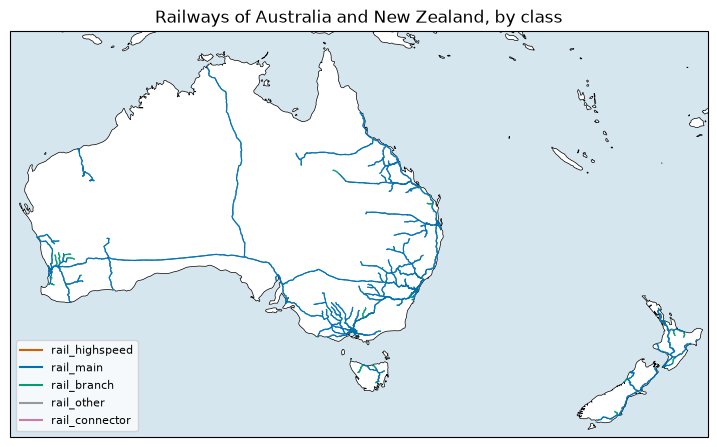

In [5]:
def draw_lines(features, colors, title, extent=(112, 179, -48, -9)):
    """A map of the lines of some GeoJSON features, each with its color.

    `extent` is [west, east, south, north] in degrees.
    """
    figure = plt.figure(figsize=(9, 6))
    ax = figure.add_subplot(projection=ccrs.PlateCarree())
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cartopy.feature.OCEAN.with_scale("50m"), facecolor="#d6e6ef")
    ax.coastlines("50m", linewidth=0.5)
    lines = [feature["geometry"]["coordinates"] for feature in features]
    ax.add_collection(LineCollection(lines, colors=colors, linewidths=0.8, transform=ccrs.PlateCarree()))
    ax.set_title(title)
    return figure, ax


CLASS_COLORS = {"rail_highspeed": "#D55E00", "rail_main": "#0072B2", "rail_branch": "#009E73", "rail_other": "#999999", "rail_connector": "#CC79A7"}

figure, ax = draw_lines(
    features,
    [CLASS_COLORS[feature["properties"]["edge_class"]] for feature in features],
    "Railways of Australia and New Zealand, by class",
)
for edge_class, color in CLASS_COLORS.items():
    ax.plot([], [], color=color, label=edge_class)
ax.legend(loc="lower left", fontsize=8)
plt.show()

The same file gives a map of the speeds. The next map divides `distance` by `metric_hours`, which gives the speed in km/h. The closed edges, with `null`, are grey.

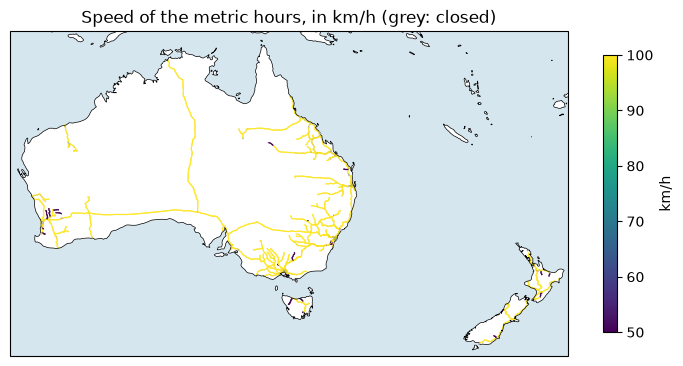

16,258 open edges, 4,690 closed edges


In [6]:
open_features = [feature for feature in features if feature["properties"]["metric_hours"] is not None]
closed_features = [feature for feature in features if feature["properties"]["metric_hours"] is None]
speeds_kmh = [feature["properties"]["distance"] / feature["properties"]["metric_hours"] for feature in open_features]

figure, ax = draw_lines(closed_features, "#bbbbbb", "Speed of the metric hours, in km/h (grey: closed)")
speed_lines = LineCollection(
    [feature["geometry"]["coordinates"] for feature in open_features],
    array=speeds_kmh,
    cmap="viridis",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=1,  # under the grey lines of the closed edges, which are short
)
ax.add_collection(speed_lines)
figure.colorbar(speed_lines, ax=ax, shrink=0.6, label="km/h")
plt.show()
print(f"{len(open_features):,} open edges, {len(closed_features):,} closed edges")

## 5. Choose the metrics to save

By default, the file holds every metric of the geograph. `metrics` chooses some of them. Here the geograph has two metrics, `hours` and `cost`, and the file holds only `hours`.

In [7]:
rail.create_metric("cost", weight_per_km={"rail": 0.05}, off_graph_weight_per_km=0.5)  # dollars, an example

rail.save_as_geojson(folder / "oceania_rail_hours.geojson", metrics=["hours"])
with open(folder / "oceania_rail_hours.geojson") as file:
    print(list(json.load(file)["features"][0]["properties"]))

['origin_idx', 'destination_idx', 'distance', 'edge_class', 'edge_mode', 'metric_hours']


## 6. Save a part of a network file

`load_from_scgraph` loads a part of a network file in the same way. Here it loads only the airports and their flights from the file of `oceania`.

The data of a released network keeps the licenses of its sources. The credit line `attribution` names these sources. A GeoJSON file that you save from the network holds the same data, so keep the credit line with the file.

In [8]:
flights = GeoGraph.load_from_scgraph(rail.scgraph_file, node_modes=["airport"])
flights.save_as_geojson(folder / "flights.geojson")

size = os.path.getsize(folder / "flights.geojson")
print(f"{len(flights.get_edges()):,} flights, {size / 1e6:.1f} MB")
print(GeoGraph.get_scgraph_info(rail.scgraph_file)["attribution"])

28,348 flights, 7.3 MB
Eurostat, SeaRoute maritime network (from the Oak Ridge National Laboratory Global Shipping Lane Network, 2000, enriched with AIS-based lines around European coasts) (EUPL-1.2); Natural Earth (1:10m) (LicenseRef-public-domain); National Geospatial-Intelligence Agency, World Port Index (Pub. 150) (LicenseRef-US-Government-Work); OurAirports (LicenseRef-public-domain); The OpenSky Network, flight list (Strohmeier et al., Earth Syst. Sci. Data 13, 357-366, 2021); US Bureau of Transportation Statistics, T-100 Segment; Eurostat, air transport routes (avia_par, avia_gor) (CC-BY-4.0); Wikidata (CC0-1.0); © OpenStreetMap contributors (ODbL-1.0)


The size of a GeoJSON file grows with the number of edges and with the points of their shapes. The first file above gives the number of bytes for each edge. A whole region, with its roads, has millions of edges, and its file is much larger than its network file. Save a part: load some node modes with `node_modes`, or cut an area with `derive_network_file`.

## 7. Save a warehouse grid

A `GridGraph` is a grid of cells, some of them blocked. Here a warehouse of 40 m by 20 m has cells of 1 m and four racks. A rack is a block of cells.

`GridGraph.save_as_geojson` writes one line for each edge of the grid, with the same properties `origin_idx`, `destination_idx` and `distance`.

In [9]:
racks = [(x, y) for x0 in (8, 16, 24, 32) for x in (x0, x0 + 1) for y in range(4, 16)]
warehouse = GridGraph(x_size=40, y_size=20, blocks=racks, add_exterior_walls=True)
warehouse.save_as_geojson(folder / "warehouse.geojson")

with open(folder / "warehouse.geojson") as file:
    warehouse_features = json.load(file)["features"]
print(f"{len(warehouse_features):,} edges, {os.path.getsize(folder / 'warehouse.geojson') / 1e3:.0f} kB")

4,020 edges, 678 kB


The next cell draws the file on plain matplotlib axes, with the shortest path from `(2, 10)` to `(37, 10)` on top. The racks show as holes in the mesh: a blocked cell has no edge.

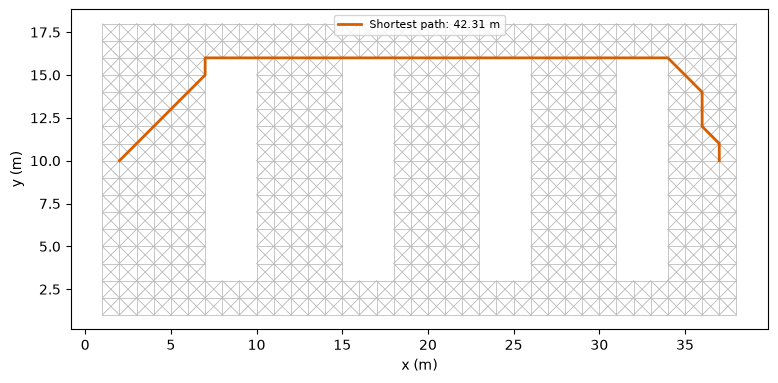

In [10]:
path = warehouse.get_shortest_path(
    origin_node={"x": 2, "y": 10},
    destination_node={"x": 37, "y": 10},
    output_coordinate_path="list_of_lists",
)

figure, ax = plt.subplots(figsize=(9, 4.5))
ax.add_collection(LineCollection([feature["geometry"]["coordinates"] for feature in warehouse_features], colors="#bbbbbb", linewidths=0.4))
ax.plot(*zip(*path["coordinate_path"]), color="#D55E00", linewidth=2, label=f"Shortest path: {path['length']:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="upper center", fontsize=8)
plt.show()

The points of this file are metres, not degrees. GeoJSON assumes longitudes and latitudes. A web map such as geojson.io reads `[x, y]` as `[longitude, latitude]`, and puts the warehouse at a wrong place on the Earth. Draw the file on plain axes, as above, with geopandas without a coordinate system, or in a QGIS project without one.

## What to remember

- `node_modes` of `load_geograph` and `load_from_scgraph` loads a part of a network.
- `save_as_geojson` writes the class, the edge mode and the weight in each metric of each edge. A closed edge gets `null`.
- `metrics` chooses the metrics to write.
- `GridGraph.save_as_geojson` writes a grid with `[x, y]` points.